# Provisionnement : Chain-Ladder, Mack et Cape Cod face au machine learning

Ce notebook reprend le backtest de `main.py` étape par étape, avec les résultats affichés.

Données : CAS Loss Reserving Database (Casualty Actuarial Society), données publiques d'assureurs américains.
Pour le relancer : `pip install -r requirements.txt`, puis exécuter les cellules (environ 1 minute ; les données sont téléchargées au premier lancement).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # accès au dossier src/

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.data import LINES, N, build_triangles, load_long, upper_mask
from src.chainladder import cape_cod, chain_ladder, mack, mack_interval
from src.backtest import classical_reserves, summarize, true_reserve
from src.ml import cross_fitted_reserves
from src import plots

pd.set_option("display.float_format", "{:,.2f}".format)
FIG = Path("../outputs/figures")

## 1. Validation des méthodes sur le triangle RAA (Mack, 1993)

Triangle de référence de la littérature : on doit retrouver une réserve totale de 52 135 et une erreur standard de Mack de 26 909.

In [2]:
RAA = [
    [5012, 8269, 10907, 11805, 13539, 16181, 18009, 18608, 18662, 18834],
    [106, 4285, 5396, 10666, 13782, 15599, 15496, 16169, 16704],
    [3410, 8992, 13873, 16141, 18735, 22214, 22863, 23466],
    [5655, 11555, 15766, 21266, 23425, 26083, 27067],
    [1092, 9565, 15836, 22169, 25955, 26180],
    [1513, 6445, 11702, 12935, 15852],
    [557, 4020, 10946, 12314],
    [1351, 6947, 13112],
    [3133, 5395],
    [2063],
]
C = np.zeros((10, 10))
for i, row in enumerate(RAA):
    C[i, :len(row)] = row
res = mack(C)
pd.DataFrame({
    "Année": range(1981, 1991),
    "Dernier paiement": res["latest"],
    "Facteur cumulé": res["cdf"],
    "Ultime": res["ultimate"],
    "Réserve": res["reserve"],
    "Erreur std Mack": res["se"],
})

,Année,Dernier paiement,Facteur cumulé,Ultime,Réserve,Erreur std Mack
0,1981,"18,834.00",1.00,"18,834.00",0.00,0.00
1,1982,"16,704.00",1.01,"16,857.95",153.95,206.22
2,1983,"23,466.00",1.03,"24,083.37",617.37,623.38
3,1984,"27,067.00",1.06,"28,703.14","1,636.14",747.18
4,1985,"26,180.00",1.10,"28,926.74","2,746.74","1,469.46"
5,1986,"15,852.00",1.23,"19,501.10","3,649.10","2,001.86"
6,1987,"12,314.00",1.44,"17,749.30","5,435.30","2,209.24"
7,1988,"13,112.00",1.83,"24,019.19","10,907.19","5,357.87"
8,1989,"5,395.00",2.97,"16,044.98","10,649.98","6,333.17"
9,1990,"2,063.00",8.92,"18,402.44","16,339.44","24,566.29"


In [3]:
lo, hi = mack_interval(res["reserve"].sum(), res["total_se"])
print(f"Réserve totale : {res['reserve'].sum():,.0f} | erreur standard de Mack : {res['total_se']:,.0f}")
print(f"Intervalle de prédiction à 95 % : [{lo:,.0f} ; {hi:,.0f}]")
print("Facteurs de développement :", np.round(res["factors"], 3))

Réserve totale : 52,135 | erreur standard de Mack : 26,909
Intervalle de prédiction à 95 % : [17,872 ; 120,092]
Facteurs de développement : [2.999 1.624 1.271 1.172 1.113 1.042 1.033 1.017 1.009]


## 2. Les données CAS : 343 triangles réels

Chaque triangle est un carré 10 × 10 : la partie haute était connue fin 1997, la partie basse s'est réalisée ensuite.

In [4]:
triangles = build_triangles(load_long())
counts = pd.Series([LINES[k[0]] for k in triangles]).value_counts()
print(f"{len(triangles)} triangles retenus après contrôle qualité")
counts.to_frame("triangles")

343 triangles retenus après contrôle qualité


,triangles
RC générale,93
Auto particuliers,86
Auto commerciale,83
Accidents du travail,56
RC produits,13
RC médicale,12


In [5]:
key = sorted(k for k in triangles if k[0] == "ppauto")[10]
tri = triangles[key]
known = pd.DataFrame(np.where(upper_mask(), tri["paid"], np.nan),
                     index=range(1988, 1998), columns=range(1, 11))
print("Paiements cumulés connus fin 1997 (milliers de $), un assureur auto :")
known

Paiements cumulés connus fin 1997 (milliers de $), un assureur auto :


,1,2,3,4,5,6,7,8,9,10
1988,"5,135.00","11,980.00","16,368.00","18,163.00","20,189.00","20,462.00","20,715.00","20,749.00","20,720.00","20,813.00"
1989,"5,655.00","15,108.00","19,498.00","23,097.00","23,819.00","24,296.00","24,622.00","24,735.00","24,736.00",NaN
1990,"6,648.00","17,982.00","23,078.00","25,334.00","26,596.00","26,983.00","27,096.00","27,150.00",NaN,NaN
1991,"5,722.00","14,677.00","19,356.00","21,906.00","22,497.00","22,732.00","23,149.00",NaN,NaN,NaN
1992,"5,906.00","14,864.00","18,305.00","20,075.00","21,779.00","22,277.00",NaN,NaN,NaN,NaN
1993,"6,439.00","15,146.00","19,187.00","21,576.00","22,539.00",NaN,NaN,NaN,NaN,NaN
1994,"6,934.00","15,703.00","19,748.00","21,300.00",NaN,NaN,NaN,NaN,NaN,NaN
1995,"6,194.00","12,183.00","15,282.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1996,"5,314.00","10,915.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1997,"4,301.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
cl = chain_ladder(np.where(upper_mask(), tri["paid"], 0))
print(f"Réserve Chain-Ladder : {cl['reserve'].sum():,.0f} | réserve réelle : {true_reserve(tri['paid']):,.0f}")

Réserve Chain-Ladder : 24,847 | réserve réelle : 21,332


## 3. Backtest des méthodes classiques et du modèle XGBoost

XGBoost apprend une correction de Chain-Ladder ; chaque compagnie est provisionnée par un modèle entraîné sur les autres compagnies.

In [7]:
df = classical_reserves(triangles)
ml_reserves, boosters = cross_fitted_reserves(triangles)
df["ml"] = [ml_reserves[(l, c)] for l, c in zip(df["line"], df["company"])]
df[["line", "company", "premium", "true", "chain_ladder", "cape_cod", "ml", "mack_lo", "mack_hi"]].head(8)

,line,company,premium,true,chain_ladder,cape_cod,ml,mack_lo,mack_hi
0,comauto,353,"52,429.00","7,399.00","6,576.44","5,764.88","4,719.69","4,200.59","9,823.62"
1,comauto,388,"1,086,150.00","189,270.00","157,873.24","149,057.17","160,287.06","85,807.60","267,086.27"
2,comauto,620,"553,119.00","89,855.00","99,778.98","89,617.96","90,199.19","82,519.05","119,573.70"
3,comauto,671,"59,467.00","13,739.00","19,480.45","15,725.00","14,825.36","14,787.34","25,193.27"
4,comauto,715,"142,808.00","27,777.00","33,796.40","32,450.95","31,906.11","28,067.53","40,347.27"
5,comauto,833,"31,134.00","2,959.00","3,696.33","3,947.13","2,993.96","2,325.19","5,589.12"
6,comauto,965,"28,834.00","6,659.00","5,775.10","6,093.44","4,180.85","3,555.22","8,882.86"
7,comauto,1066,"96,880.00","5,269.00","14,675.85","13,145.37","11,489.21","8,446.76","23,781.18"


In [8]:
summary = summarize(df, ["chain_ladder", "cape_cod", "ml"])
summary["branche"] = summary["branche"].map(lambda b: LINES.get(b, b))
cols = {
    "chain_ladder_rmse_pct_prime": "CL : erreur quadratique (% primes)",
    "cape_cod_rmse_pct_prime": "Cape Cod : erreur quadratique (% primes)",
    "ml_rmse_pct_prime": "XGBoost : erreur quadratique (% primes)",
    "chain_ladder_biais_total_pct": "CL : biais (%)",
    "ml_biais_total_pct": "XGBoost : biais (%)",
    "ml_meilleur_que_cl_pct": "XGBoost meilleur que CL (% triangles)",
    "couverture_mack_95_pct": "Couverture Mack 95 % (%)",
}
summary.set_index("branche")[list(cols)].rename(columns=cols).T

branche,Toutes branches,Auto commerciale,RC médicale,RC générale,Auto particuliers,RC produits,Accidents du travail
CL : erreur quadratique (% primes),6.60,5.71,15.11,6.25,4.86,14.85,4.17
Cape Cod : erreur quadratique (% primes),5.42,5.03,6.97,6.01,4.61,9.59,4.28
XGBoost : erreur quadratique (% primes),4.53,4.45,7.61,5.36,3.45,5.99,3.07
CL : biais (%),12.83,8.15,31.64,35.88,10.87,9.61,7.57
XGBoost : biais (%),-5.98,-9.90,3.51,-4.07,-7.61,-20.27,5.97
XGBoost meilleur que CL (% triangles),56.27,59.04,75.00,55.91,55.81,38.46,53.57
Couverture Mack 95 % (%),76.68,85.54,66.67,87.10,69.77,84.62,57.14


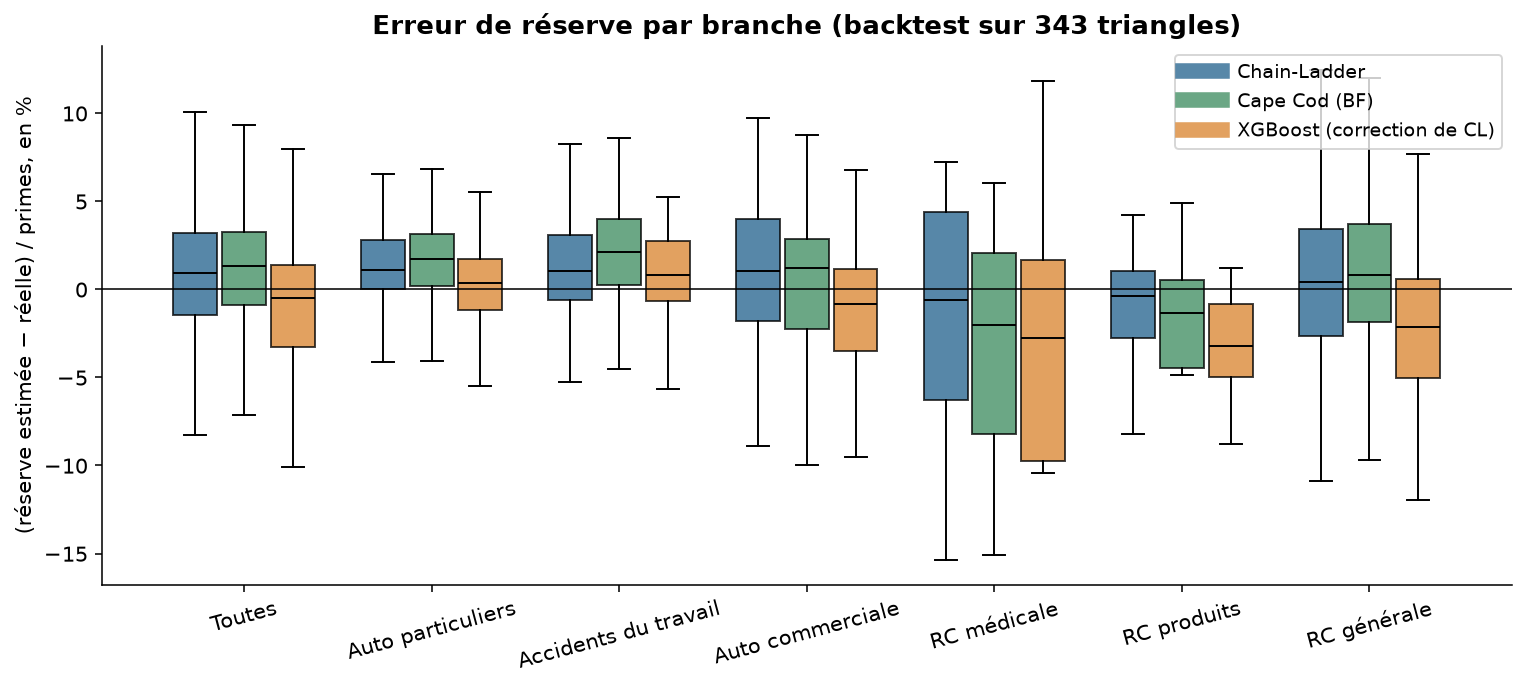

In [9]:
plots.errors_by_line(df, ["chain_ladder", "cape_cod", "ml"], FIG / "erreurs_par_branche.png")
display(Image(FIG / "erreurs_par_branche.png"))

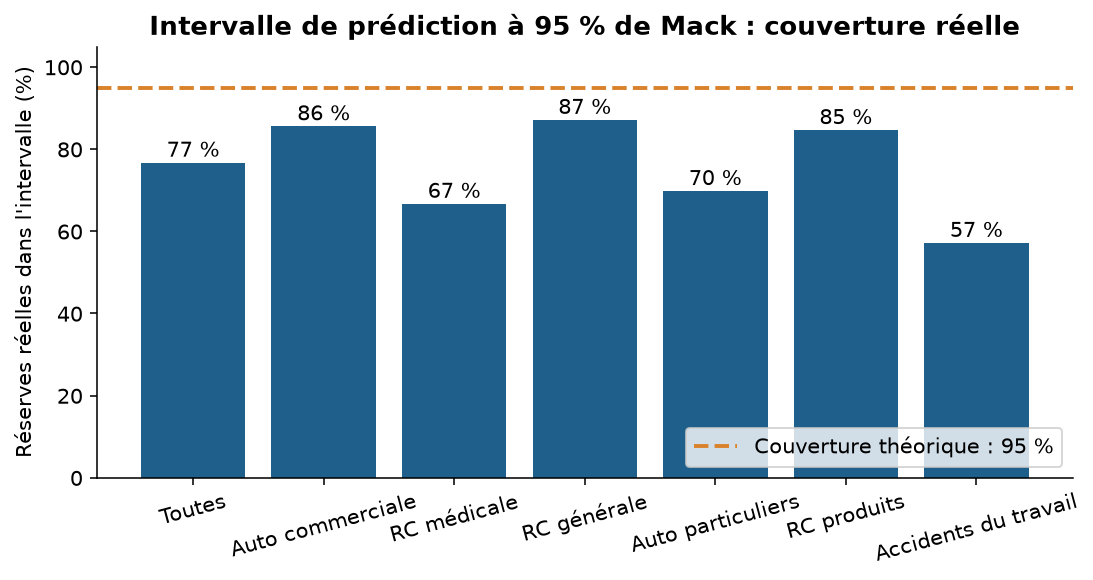

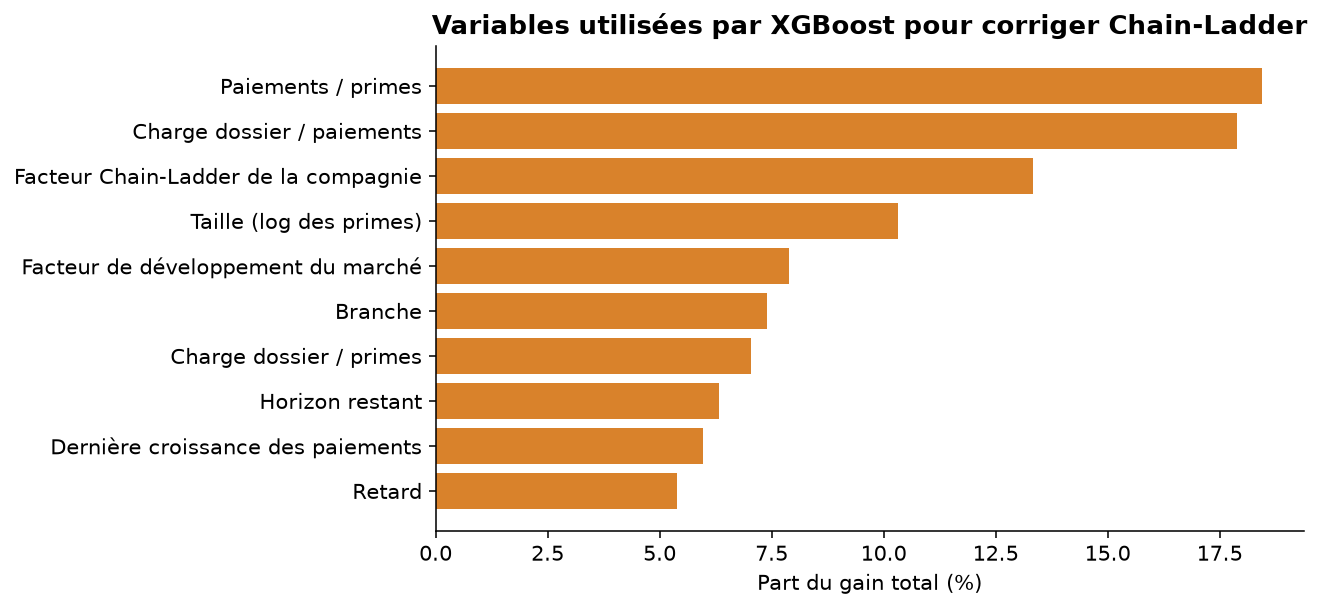

In [10]:
plots.mack_coverage(summarize(df, ["chain_ladder", "cape_cod", "ml"]), FIG / "couverture_mack.png")
plots.feature_importance(boosters, FIG / "variables_xgboost.png")
display(Image(FIG / "couverture_mack.png"))
display(Image(FIG / "variables_xgboost.png"))

## Conclusion

- XGBoost, utilisé comme correction de Chain-Ladder, réduit surtout les grosses erreurs (erreur quadratique 4,5 % des primes contre 6,6 % pour Chain-Ladder).
- Les provisions dossier (charge dossier / paiements) sont l'information la plus utile après le niveau de sinistralité.
- Le modèle sous-estime légèrement les réserves, quand Chain-Ladder les surestime : un modèle ML doit rester un second avis.
- L'intervalle à 95 % de Mack est trop étroit (77 % de couverture réelle), comme l'a montré Meyers (2015) sur la même base.